In [2]:
from rdkit import Chem
from rdkit.Chem import AllChem
from rdkit.DataStructs import BulkTanimotoSimilarity
from rdkit.ML.Cluster import Butina
import numpy as np
import pandas as pd
from rdkit import Chem
from rdkit.Chem import AllChem
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score
import os 
from padelpy import padeldescriptor
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score
from rdkit.Chem import rdFingerprintGenerator  
import pandas as pd 
from padelpy import from_smiles
import warnings
warnings.filterwarnings('ignore')


import numpy as np
import pandas as pd
from rdkit import Chem
from rdkit.Chem import Descriptors
from rdkit.Chem.rdFingerprintGenerator import GetMorganGenerator
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

In [3]:
df= pd.read_csv('cleaned_data.csv')
df.head()

,SMILES,VERIFY,ESOL Class,MW_pub,BBB,hERG,Ames,H-HT
0,B1(OC(C(O1)(C)C)(C)C)C2=CC3=C(CC4(C35C(=O)N(C(...,False,Moderately soluble,468.4,0.982377,0.138762,0.684111,0.349169
1,B1(OC(C(O1)(C)C)(C)C)C2=CC3=C(CC4(C35C(=O)N(C(...,False,Moderately soluble,476.3,0.999029,0.262471,0.351038,0.586856
2,B1(OC(C(O1)(C)C)(C)C)C2=CC3=C(CC4(C35C(=O)N(C(...,True,Moderately soluble,472.4,0.989686,0.112066,0.887385,0.556827
3,C#CCOC1=CN=C(C=C1)C(=O)NC2=CC(=C(C(=C2)F)F)[C@...,True,Moderately soluble,486.4,0.001523,0.666432,0.854345,0.977018
4,C#CCOC1=CN=C(C=C1)C(=O)NC2=CC(=C(C=C2)F)[C@@]3...,False,Soluble,430.4,0.004441,0.332171,0.871076,0.912706


In [19]:
df.columns

Index(['SMILES', 'VERIFY', 'ESOL Class', 'MW_pub', 'BBB', 'hERG', 'Ames',
       'H-HT'],
      dtype='str')

In [ ]:


# 1. Initialize the modern fingerprint generator
morgan_gen = GetMorganGenerator(radius=2, fpSize=1024)

# 2. Your feature extractor, structured cleanly to separate types
def extract_molecular_features(smiles):
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        return None, None
    
    # Structural features (1024 bits of 0 and 1)
    fp = morgan_gen.GetFingerprintAsNumPy(mol)
    
    # Physical-chemical descriptors
    phys_chem = np.array([
        Descriptors.MolLogP(mol),       # Lipophilicity
        Descriptors.TPSA(mol),          # Topological Polar Surface Area
        Descriptors.MolWt(mol),         # Molecular Weight
        Descriptors.NumHDonors(mol),    # H-Bond Donors
        Descriptors.NumHAcceptors(mol)  # H-Bond Acceptors
    ])
    
    return fp, phys_chem

# --- Pipeline Execution ---

# Extract parallel feature arrays
fps_list = []
phys_list = []
valid_smiles = []

for smiles in df['SMILES'].unique():
    fp, phys = extract_molecular_features(smiles)
    if fp is not None:
        fps_list.append(fp)
        phys_list.append(phys)
        valid_smiles.append(smiles)

X_fp = np.stack(fps_list)          # Shape: (N, 1024)
X_phys = np.stack(phys_list)      # Shape: (N, 5)

# 3. CRITICAL STEP: Scale the physical properties so they are on a 0-to-1 scale
# This prevents Molecular Weight (e.g. 400) from overpowering a bit-vector (0 or 1)
scaler = StandardScaler()
X_phys_scaled = scaler.fit_transform(X_phys)

# 4. Optional: Weighting the physiochemical properties
# Because there are only 5 physical properties vs 1024 binary bits, we can multiply
# the physical properties by a scaling factor (e.g., 2.0 or 3.0) to give them more "say" in the clustering.
weight_factor = 2.0
X_phys_weighted = X_phys_scaled * weight_factor

# 5. Concatenate the balanced feature sets
X_combined = np.concatenate([X_fp, X_phys_weighted], axis=1)

# 6. Apply Clustering (e.g., K-Means)
num_clusters = 8  # Adjust based on your preferred cluster resolution
kmeans = KMeans(n_clusters=num_clusters, random_state=42, n_init=10)

cluster_labels = kmeans.fit_predict(X_combined)

# 7. Package into a clean DataFrame
df_clusters = pd.DataFrame({
    'SMILES': valid_smiles,
    'Cluster_ID': cluster_labels,
    'LogP': X_phys[:, 0],
    'TPSA': X_phys[:, 1],
    'MW': X_phys[:, 2]
})

print(f"Successfully generated {num_clusters} multi-property clusters!")
print(df_clusters.head())

Successfully generated 8 multi-property clusters!
                                              SMILES  Cluster_ID    LogP  \
0  B1(OC(C(O1)(C)C)(C)C)C2=CC3=C(CC4(C35C(=O)N(C(...           0  3.2728   
1  B1(OC(C(O1)(C)C)(C)C)C2=CC3=C(CC4(C35C(=O)N(C(...           0  3.0870   
2  B1(OC(C(O1)(C)C)(C)C)C2=CC3=C(CC4(C35C(=O)N(C(...           0  2.8339   
3  C#CCOC1=CN=C(C=C1)C(=O)NC2=CC(=C(C(=C2)F)F)[C@...           2  3.4548   
4  C#CCOC1=CN=C(C=C1)C(=O)NC2=CC(=C(C=C2)F)[C@@]3...           7  2.6788   

    TPSA       MW  
0  77.10  468.403  
1  77.10  476.329  
2  77.10  472.366  
3  98.83  486.372  
4  98.83  430.386  


In [14]:
df_clusters[df_clusters['Cluster_ID'] == 0]

,SMILES,Cluster_ID,LogP,TPSA,MW
0,B1(OC(C(O1)(C)C)(C)C)C2=CC3=C(CC4(C35C(=O)N(C(...,0,3.27280,77.10,468.403
1,B1(OC(C(O1)(C)C)(C)C)C2=CC3=C(CC4(C35C(=O)N(C(...,0,3.08700,77.10,476.329
2,B1(OC(C(O1)(C)C)(C)C)C2=CC3=C(CC4(C35C(=O)N(C(...,0,2.83390,77.10,472.366
198,CC#CC1=CSC(=N1)C2=CC3=C(CC4(C35C(=O)N(C(=N5)N)...,0,4.07360,80.81,462.619
239,CC(C)CCC1=CC2=C(CC3(C24C(=O)N(C(=N4)N)CCOC)CCC...,0,3.40530,77.15,427.589
...,...,...,...,...,...
794,C[C@@H]1CC2(C[C@@H](C1OC)C)CC3=C([C@@]24C(=O)N...,0,2.71298,100.94,436.556
795,C[C@@H]1CC2(C[C@@H](C1OC)C)CC3=C([C@@]24C(=O)N...,0,1.94938,110.17,452.555
833,C[C@H]1C[C@@]2(CC[C@@H]1O)CC3=C([C@@]24C(=O)N(...,0,2.81440,117.59,468.561
834,C[C@H]1C[C@@]2(CC[C@@H]1O)CC3=C([C@@]24C(=O)N(...,0,2.67918,102.71,428.483


Reducing dimensions with t-SNE... (this should now run cleanly)


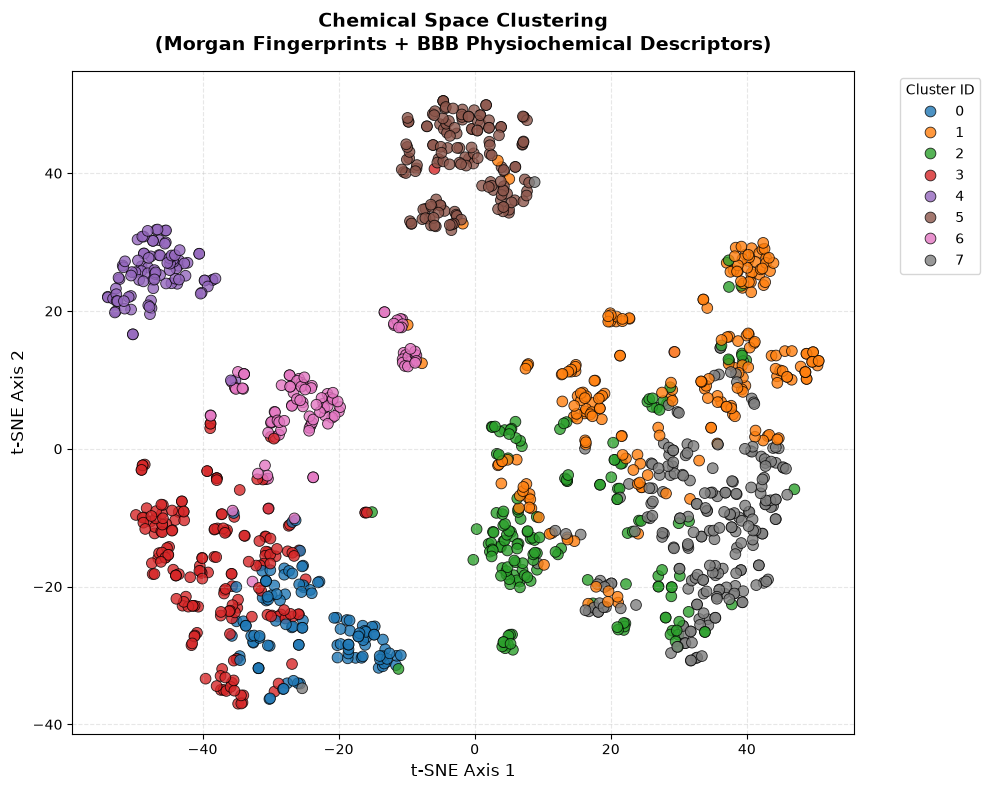

In [15]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.manifold import TSNE

# 1. Initialize t-SNE using the modern parameter name 'max_iter'
tsne = TSNE(
    n_components=2, 
    perplexity=30, 
    random_state=42, 
    max_iter=1000  # <--- Changed from n_iter to max_iter
)

print("Reducing dimensions with t-SNE... (this should now run cleanly)")
X_tsne = tsne.fit_transform(X_combined)

# 2. Add coordinates back into the tracking DataFrame
df_clusters['tSNE_1'] = X_tsne[:, 0]
df_clusters['tSNE_2'] = X_tsne[:, 1]

# 3. Create the Scatter Plot
plt.figure(figsize=(10, 8))
sns.scatterplot(
    x='tSNE_1', 
    y='tSNE_2', 
    hue='Cluster_ID', 
    palette='tab10', 
    data=df_clusters,
    alpha=0.8,
    edgecolor='k',
    s=60
)

# 4. Polish the plot aesthetics
plt.title('Chemical Space Clustering\n(Morgan Fingerprints + BBB Physiochemical Descriptors)', 
          fontsize=14, fontweight='bold', pad=15)
plt.xlabel('t-SNE Axis 1', fontsize=12)
plt.ylabel('t-SNE Axis 2', fontsize=12)
plt.legend(title='Cluster ID', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, linestyle='--', alpha=0.3)

plt.tight_layout()
plt.show()

In [20]:
import numpy as np
import pandas as pd
from rdkit import Chem
from rdkit.Chem import Descriptors
from rdkit.Chem.rdFingerprintGenerator import GetMorganGenerator
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

# 1. Initialize structural fingerprint engine
morgan_gen = GetMorganGenerator(radius=2, fpSize=1024)

# 2. Extract structural + calculated physicochemical properties
fps_list = []
phys_list = []
valid_indices = []

print("Extracting structures and physiochemical features...")
for idx, row in df.iterrows():
    mol = Chem.MolFromSmiles(row['SMILES'])
    if mol is not None:
        fp = morgan_gen.GetFingerprintAsNumPy(mol)
        phys = np.array([
            Descriptors.MolLogP(mol),
            Descriptors.TPSA(mol),
            Descriptors.MolWt(mol),
            Descriptors.NumHDonors(mol),
            Descriptors.NumHAcceptors(mol)
        ])
        fps_list.append(fp)
        phys_list.append(phys)
        valid_indices.append(idx)

# Filter the original dataframe to keep only valid RDKit molecules
df_clean = df.loc[valid_indices].copy()

X_fp = np.stack(fps_list)    # Structural matrix
X_phys = np.stack(phys_list)  # Calculated properties matrix

# 3. Pull and prepare your assay columns
# Select continuous and binary assay targets
assay_cols = ['BBB', 'hERG', 'Ames', 'VERIFY', 'MW_pub', 'H-HT']
X_assays = df_clean[assay_cols].fillna(df_clean[assay_cols].median()).values

# Handle Categorical Columns (e.g., 'ESOL Class') using One-Hot Encoding
X_categorical = pd.get_dummies(df_clean['ESOL Class'], drop_first=True).values

# 4. CRITICAL: Combine and Scale all non-fingerprint features together
# This forces MW, LogP, and binary targets into the same mathematical scale
X_numerical_combined = np.concatenate([X_phys, X_assays, X_categorical], axis=1)

scaler = StandardScaler()
X_numerical_scaled = scaler.fit_transform(X_numerical_combined)

# 5. Balance the weight between structure (1024 bits) and properties
# Multiply properties by a weight factor so they aren't ignored by the 1024 bits
weight_factor = 2.5
X_numerical_weighted = X_numerical_scaled * weight_factor

# 6. Final Feature Matrix for K-Means
X_final_cluster = np.concatenate([X_fp, X_numerical_weighted], axis=1)

# 7. Cluster
num_clusters = 6
kmeans = KMeans(n_clusters=num_clusters, random_state=42, n_init=10)
df_clean['Comprehensive_Cluster_ID'] = kmeans.fit_predict(X_final_cluster)

print(f"\nSuccessfully generated {num_clusters} comprehensive profile clusters!")
print(df_clean[['SMILES', 'Comprehensive_Cluster_ID'] + assay_cols].head())

Extracting structures and physiochemical features...

Successfully generated 6 comprehensive profile clusters!
                                              SMILES  \
0  B1(OC(C(O1)(C)C)(C)C)C2=CC3=C(CC4(C35C(=O)N(C(...   
1  B1(OC(C(O1)(C)C)(C)C)C2=CC3=C(CC4(C35C(=O)N(C(...   
2  B1(OC(C(O1)(C)C)(C)C)C2=CC3=C(CC4(C35C(=O)N(C(...   
3  C#CCOC1=CN=C(C=C1)C(=O)NC2=CC(=C(C(=C2)F)F)[C@...   
4  C#CCOC1=CN=C(C=C1)C(=O)NC2=CC(=C(C=C2)F)[C@@]3...   

   Comprehensive_Cluster_ID       BBB      hERG      Ames  VERIFY  MW_pub  \
0                         3  0.982377  0.138762  0.684111   False   468.4   
1                         3  0.999029  0.262471  0.351038   False   476.3   
2                         3  0.989686  0.112066  0.887385    True   472.4   
3                         2  0.001523  0.666432  0.854345    True   486.4   
4                         5  0.004441  0.332171  0.871076   False   430.4   

       H-HT  
0  0.349169  
1  0.586856  
2  0.556827  
3  0.977018  
4  0.912706  


Reducing dimensions with t-SNE for the comprehensive features...


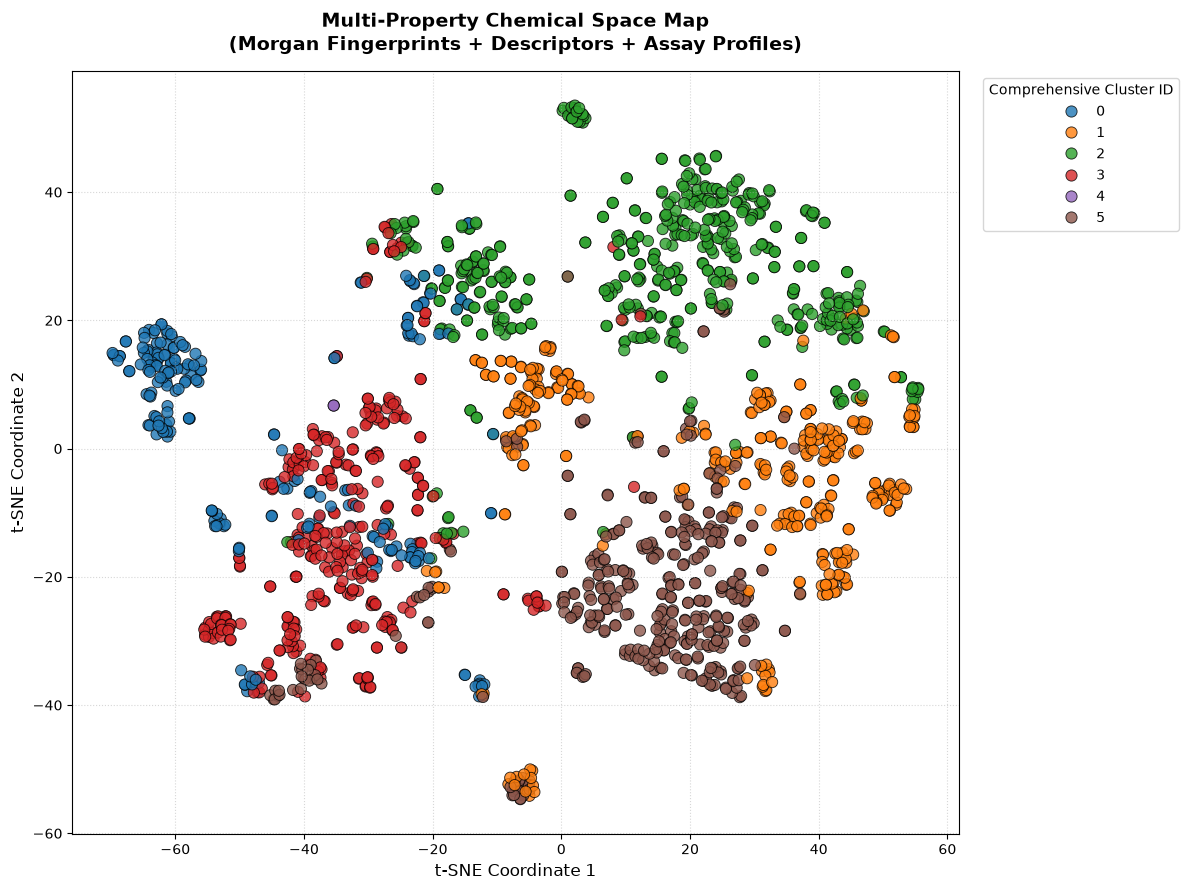

In [21]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.manifold import TSNE

# 1. Initialize t-SNE with the corrected 'max_iter' parameter
tsne = TSNE(
    n_components=2, 
    perplexity=30, 
    random_state=42, 
    max_iter=1000
)

print("Reducing dimensions with t-SNE for the comprehensive features...")
X_tsne = tsne.fit_transform(X_final_cluster)

# 2. Assign coordinates back to your clean dataset
df_clean['tSNE_1'] = X_tsne[:, 0]
df_clean['tSNE_2'] = X_tsne[:, 1]

# 3. Create the Scatter Plot
plt.figure(figsize=(12, 9))

sns.scatterplot(
    x='tSNE_1', 
    y='tSNE_2', 
    hue='Comprehensive_Cluster_ID', 
    palette='tab10',  # Clean categorical palette for distinct cluster coloring
    data=df_clean,
    alpha=0.8,
    edgecolor='k',    # Adds a black boundary to separate overlapping markers
    s=65              # Size of the molecular data points
)

# 4. Polish plot formatting and typography
plt.title(
    'Multi-Property Chemical Space Map\n'
    '(Morgan Fingerprints + Descriptors + Assay Profiles)', 
    fontsize=14, 
    fontweight='bold', 
    pad=15
)
plt.xlabel('t-SNE Coordinate 1', fontsize=12)
plt.ylabel('t-SNE Coordinate 2', fontsize=12)

# Place legend cleanly outside the plot area
plt.legend(
    title='Comprehensive Cluster ID', 
    bbox_to_anchor=(1.02, 1), 
    loc='upper left', 
    fontsize=10
)
plt.grid(True, linestyle=':', alpha=0.5)

plt.tight_layout()
plt.show()

In [22]:
# Check what each cluster mathematically represents
profile_summary = df_clean.groupby('Comprehensive_Cluster_ID')[['BBB', 'hERG', 'Ames', 'VERIFY']].mean()
print(profile_summary)

                               BBB      hERG      Ames    VERIFY
Comprehensive_Cluster_ID                                        
0                         0.144938  0.777029  0.763437  0.864035
1                         0.082420  0.466066  0.691545  0.560647
2                         0.156981  0.649893  0.643708  0.477670
3                         0.378300  0.608202  0.524333  0.752874
4                         0.693412  0.462996  0.462151  0.500000
5                         0.136504  0.676466  0.749262  0.628788


In [5]:
from padelpy import from_smiles

# Calculate all 2D descriptors (including E-state and HB descriptors)
descriptors = from_smiles("CC(=O)Oc1ccccc1C(=O)O", output_csv="descriptors.csv")

In [6]:
from rdkit import Chem
from rdkit.Chem import EState

# Convert SMILES to an RDKit Molecule object
mol = Chem.MolFromSmiles("CC(=O)Oc1ccccc1C(=O)O")

# Calculate E-State values for the atoms
estate_values = EState.EStateIndices(mol)

In [7]:
estate_values

array([ 1.22086357, -0.53361111, 10.57281935,  4.68689815,  0.07175926,
        1.43537037,  1.60189815,  1.56592215,  1.37560185, -0.01601852,
       -1.11402778, 10.61194822,  8.68724301])